# Experimento de ML: volume mensal da Ouvidoria de Poá

## Contexto e método

**Pergunta:** o histórico mensal ajuda a estimar o volume agregado de manifestações registradas da Ouvidoria de Poá? O possível uso é explorar a cadência de informação pública. A série não discrimina serviços e não sustenta previsão operacional.

A fonte primária é o Relatório Anual da Ouvidoria de Poá de 2024, que publica valores mensais de 2023 e 2024. São 24 observações reais. A defasagem de um mês deixa 23 linhas supervisionadas, com mês cíclico (seno e cosseno), ano e contagem do mês anterior.

O modelo é `RandomForestRegressor` do **scikit-learn**. O holdout mantém os últimos 20% em ordem cronológica (cinco meses). A busca avalia 18 combinações com `GridSearchCV` e `TimeSeriesSplit(3)` somente no treino; os folds são 6/4, 10/4 e 14/4. A seleção minimiza MAE. O teste não participa da seleção. Como comparador, usa-se a previsão ingênua do último mês. As métricas são MAE, RMSE e R².

A escolha do Random Forest é didática: combina calendário e defasagem sem impor tendência linear. Com menos de dois ciclos anuais e cinco meses de teste, o experimento não demonstra superioridade nem utilidade operacional.

### 1. Ambiente e dependências

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import sklearn
from IPython.display import SVG, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "ml/dados/ouvidoria_poa_mensal.csv").is_file()
)
sys.path.insert(0, str(ROOT / "ml"))
from experimento_ouvidoria import (
    chronological_holdout,
    feature_matrix,
    generate_figures,
    load_monthly_data,
    prepare_supervised_rows,
    save_experiment_artifacts,
    search_rows,
    target_vector,
    validate_monthly_data,
)

print(f"scikit-learn {sklearn.__version__} | NumPy {np.__version__}")

scikit-learn 1.9.1 | NumPy 2.5.5


## Dados e controle de qualidade

O CSV documenta a fonte oficial e mantém apenas manifestações registradas. Os totais publicados foram reconciliados; as 557 ligações de 2025 sem protocolo não entram na série.

In [2]:
monthly = load_monthly_data(ROOT / "ml/dados/ouvidoria_poa_mensal.csv")
quality = validate_monthly_data(monthly)
assert quality["meses_consecutivos"] and quality["lacunas"] == 0
print("Validação:", quality)
print("Primeira observação:", monthly[0])
print("Última observação:", monthly[-1])

Validação: {'linhas': 24, 'meses_consecutivos': True, 'duplicatas': 0, 'lacunas': 0, 'totais_anuais': {'2023': 717, '2024': 853}}
Primeira observação: {'ano': 2023, 'mes': 1, 'manifestacoes_registradas': 63, 'url_fonte': 'https://poa.sp.gov.br/wp-content/uploads/2025/03/Relatorio-Ouvidoria-2024.pdf'}
Última observação: {'ano': 2024, 'mes': 12, 'manifestacoes_registradas': 24, 'url_fonte': 'https://poa.sp.gov.br/wp-content/uploads/2025/03/Relatorio-Ouvidoria-2024.pdf'}


## Preparação e divisão temporal

Janeiro de 2023 não entra na matriz supervisionada por não ter mês anterior. A variável de ano é preservada como valor numérico. Cada previsão no teste usa o valor real do mês imediatamente anterior, simulando atualização mensal.

In [3]:
supervised_rows = prepare_supervised_rows(monthly)
train_rows, test_rows = chronological_holdout(supervised_rows, test_fraction=0.20)
X_train, y_train = feature_matrix(train_rows), target_vector(train_rows)
X_test, y_test = feature_matrix(test_rows), target_vector(test_rows)

print(f"Observações originais: {len(monthly)}")
print(f"Linhas supervisionadas: {len(supervised_rows)}")
print(f"Treino: {len(train_rows)} ({train_rows[0]['mes_rotulo']} a {train_rows[-1]['mes_rotulo']})")
print(f"Teste: {len(test_rows)} ({test_rows[0]['mes_rotulo']} a {test_rows[-1]['mes_rotulo']})")
print("Features: mês seno, mês cosseno, ano e manifestações do mês anterior")

Observações originais: 24
Linhas supervisionadas: 23
Treino: 18 (02/2023 a 07/2024)
Teste: 5 (08/2024 a 12/2024)
Features: mês seno, mês cosseno, ano e manifestações do mês anterior


## Busca e validação cruzada

A validação cruzada usa uma janela expansiva do scikit-learn exclusivamente no treino. As 18 combinações e seus erros por fold ficam registradas em `ml/resultados/busca_hiperparametros.csv`.

In [4]:
time_series_cv = TimeSeriesSplit(n_splits=3)
fold_sizes = [
    (len(train_idx), len(validation_idx))
    for train_idx, validation_idx in time_series_cv.split(X_train)
]
assert fold_sizes == [(6, 4), (10, 4), (14, 4)], fold_sizes

parameter_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [2, 4, None],
    "min_samples_leaf": [1, 2],
}
search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=time_series_cv,
    refit=True,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train, y_train)
cv_table = search_rows(search.cv_results_)
assert len(cv_table) == 18
print("Melhores parâmetros:", search.best_params_)
print(f"MAE médio de CV: {-search.best_score_:.2f}")
print()
print("18 combinações ordenadas por MAE médio:")
for row in cv_table:
    print(row)

Melhores parâmetros: {'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 100}
MAE médio de CV: 22.46

18 combinações ordenadas por MAE médio:
{'n_estimators': 100, 'max_depth': '2', 'min_samples_leaf': 2, 'mae_fold_1': 20.822083333333325, 'mae_fold_2': 29.30426190476191, 'mae_fold_3': 17.24105555555557, 'mae_cv_media': 22.455800264550266}
{'n_estimators': 100, 'max_depth': '4', 'min_samples_leaf': 2, 'mae_fold_1': 20.822083333333325, 'mae_fold_2': 29.426761904761904, 'mae_fold_3': 17.34136904761906, 'mae_cv_media': 22.530071428571432}
{'n_estimators': 100, 'max_depth': 'ilimitado', 'min_samples_leaf': 2, 'mae_fold_1': 20.822083333333325, 'mae_fold_2': 29.426761904761904, 'mae_fold_3': 17.34136904761906, 'mae_cv_media': 22.530071428571432}
{'n_estimators': 200, 'max_depth': '2', 'min_samples_leaf': 2, 'mae_fold_1': 20.842395833333313, 'mae_fold_2': 28.993627976190464, 'mae_fold_3': 18.673916666666674, 'mae_cv_media': 22.836646825396816}
{'n_estimators': 200, 'max_depth': 'ilimitado'

## Avaliação em treino e teste

O melhor estimador é ajustado novamente pelo próprio `GridSearchCV` em todo o treino. O baseline repete a contagem do mês anterior. R² pode ser negativo quando o modelo fica pior do que prever a média do conjunto avaliado.

In [5]:
train_predictions = search.best_estimator_.predict(X_train)
test_predictions = search.best_estimator_.predict(X_test)
train_baseline = X_train[:, -1]
test_baseline = X_test[:, -1]

def evaluate(actual, predicted):
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": float(r2_score(actual, predicted)),
    }

experiment_metrics = {
    "modelo": {
        "treino": evaluate(y_train, train_predictions),
        "teste": evaluate(y_test, test_predictions),
    },
    "ingenua_ultimo_mes": {
        "treino": evaluate(y_train, train_baseline),
        "teste": evaluate(y_test, test_baseline),
    },
}
result = save_experiment_artifacts(
    ROOT,
    monthly,
    quality,
    train_rows,
    test_rows,
    search,
    experiment_metrics,
    train_predictions,
    test_predictions,
    train_baseline,
    test_baseline,
)
figure_paths = generate_figures(
    ROOT, monthly, test_rows, test_predictions, test_baseline, search.cv_results_
)
print(json.dumps(experiment_metrics, ensure_ascii=False, indent=2))
print("Artefatos atualizados:", ROOT / "ml/resultados")

{
  "modelo": {
    "treino": {
      "MAE": 10.754139490139492,
      "RMSE": 14.622496038633157,
      "R2": 0.6122442251551882
    },
    "teste": {
      "MAE": 19.358467388167384,
      "RMSE": 19.906259053918514,
      "R2": -0.2392392717091345
    }
  },
  "ingenua_ultimo_mes": {
    "treino": {
      "MAE": 18.61111111111111,
      "RMSE": 24.272755646334566,
      "R2": -0.06844806644986878
    },
    "teste": {
      "MAE": 18.0,
      "RMSE": 22.86482013924448,
      "R2": -0.6349762321741306
    }
  }
}
Artefatos atualizados: C:\Users\LuanRamosGarciadeSou\OneDrive - CERC S.A\Área de Trabalho\GS3ano\repositorio-nexo-llm\ml\resultados


## TL;DR

<!-- RESULT_SUMMARY_BEGIN -->
Com 18 linhas de treino e 5 de teste (08/2024 a 12/2024), o RandomForestRegressor do scikit-learn teve MAE de 19.36, RMSE de 19.91 e R² de -0.24. O baseline do último mês teve MAE de 18.00; o modelo aumentou o MAE em 7.5%. O resultado cobre apenas cinco meses e não demonstra capacidade de previsão operacional.
<!-- RESULT_SUMMARY_END -->

## Resultados e figuras

A linha vertical marca o início do teste. Os gráficos são gerados com Matplotlib e apresentados abaixo.

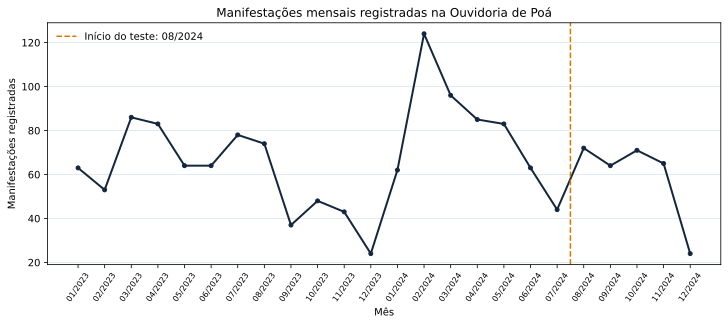

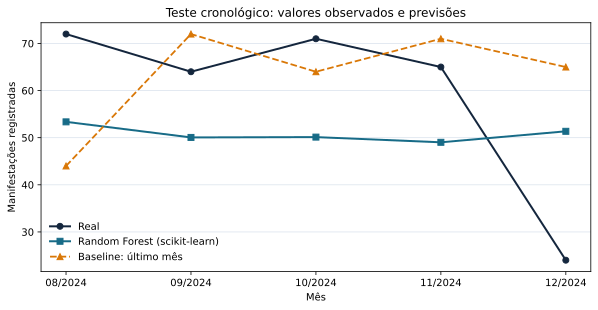

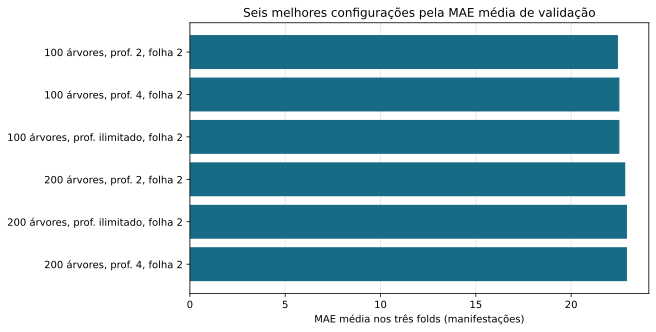

In [6]:
for figure_path in figure_paths:
    display(SVG(filename=str(figure_path)))

## Interpretação e limites

<!-- TAKEAWAYS_BEGIN -->
O MAE foi 10.75 no treino e 19.36 no teste (diferença teste menos treino: 8.60). O R² de teste foi -0.24. Esses indicadores sugerem ajuste menos estável fora do treino, mas cinco pontos de teste são insuficientes para um diagnóstico conclusivo de sobreajuste.
<!-- TAKEAWAYS_END -->

- A amostra de teste tem somente cinco pontos; as métricas são instáveis e não comprovam generalização.
- O total reúne temas diferentes e pode refletir mudanças de registro ou atendimento. Não usar para priorizar um serviço específico.
- O experimento é acadêmico e exploratório; o modelo não é integrado à API, ao painel ou ao aplicativo.

## Fontes

- [Relatório Anual da Ouvidoria de Poá 2024 (PDF)](https://poa.sp.gov.br/wp-content/uploads/2025/03/Relatorio-Ouvidoria-2024.pdf), tabela mensal, página 9.
- [Relatório Anual da Ouvidoria de Poá 2025 (PDF)](https://poa.sp.gov.br/wp-content/uploads/2026/04/Relatorio-Ouvidoria-2025.pdf), usado apenas para contextualizar o total de 1.074 manifestações e distinguir as 557 ligações sem protocolo; seus dados não entram no experimento.
- Veja `ml/dados/README.md` para extração, reconciliação e limitações.